# Used-car price prediction (AutoScout24, Germany) — regression project

**Goal:** predict the asking price of a used car from 7 features, compare four model families, deploy the best one.

**Data:** Kaggle `ander289386/cars-germany` — AutoScout24 listings scraped in 2021 (about 46k rows, 9 columns).

**Key decisions (all justified in the sections below)**

| Decision | Choice |
|---|---|
| Scope | Used cars only, price up to 100,000 EUR |
| Target | `log(price)` for training, errors reported back in EUR |
| Car age | `age = 2021 - year` (prices are 2021-era) |
| Rare categories | `OneHotEncoder(min_frequency=3)` inside the pipeline |
| Validation | One 80/20 split. All tuning uses 5-fold CV on the 80% only. The 20% test set is scored **once**. |
| Winner rule | Set before tuning: a model must beat the best linear model by more than about 1 std of CV noise (0.003 log-RMSE) |

**Sections**
1. Setup, 2. Load, 3. Inspect raw data, 4. Cleaning (structural), 5. Outlier inspection, 6. Cleaning (rules) + features, 7. Split,
8. Preprocessing and `min_frequency` experiment, 9. Baselines and model comparison, 10. Bias / variance diagnostics,
11. Hyperparameter experiments, 12. Final test evaluation, 13. Residual analysis, 14. Refit and export.

**How to run:** *Restart and run all*. A full run takes roughly an hour on Colab's free CPU, mostly the Random Forest CV (about 20 min) and the two XGBoost searches.
Flags in the config cell let you skip the slow experiments. Numbers quoted in markdown notes come from the original Colab run; re-check them after a clean run.

## 1. Setup

In [2]:
%pip install -q kagglehub catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.2 MB/s eta 0:00:00


In [3]:
import glob, json, os, time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from catboost import CatBoostRegressor
from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (KFold, RandomizedSearchCV, cross_val_score,
                                     cross_validate, learning_curve,
                                     train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [4]:
# ---------- Configuration: every tunable constant lives here ----------
SEED = 42
REF_YEAR = 2021          # the data was scraped in 2021, so age = REF_YEAR - year
MIN_FREQ = 3             # OneHotEncoder min_frequency (chosen in section 8)

NUM_COLS = ["age", "mileage", "hp"]
CAT_COLS = ["fuel", "gear", "make", "make_model"]
FEATURES = NUM_COLS + CAT_COLS

# Switches for the slow experiments. Everything downstream works with them off,
# but the comparison table will then lack the corresponding rows.
RUN_RANDOM_FOREST   = True   # about 4 min per fit on Colab CPU (about 20 min for 5 folds)
RUN_LEARNING_CURVES = True   # about 3-5 min
RUN_SEARCH_V1       = True   # first XGBoost search (wrong depth range), kept as a documented dead end

## 2. Load data

In [5]:
import kagglehub

data_dir = kagglehub.dataset_download("ander289386/cars-germany")
csv_files = glob.glob(os.path.join(data_dir, "*.csv"))
# Guard: an earlier version of this notebook picked csv_files[0] from a Drive folder that also
# held a different dataset (Craigslist vehicles.csv) and silently loaded the wrong one.
assert len(csv_files) == 1, f"expected exactly one CSV in {data_dir}, found {csv_files}"

df_raw = pd.read_csv(csv_files[0])   # never modified; every later stage works on a copy
print("Loaded:", csv_files[0], df_raw.shape)
display(df_raw.head())

100%|██████████| 498k/498k [00:00<00:00, 26.1MB/s]

Extracting files...
Loaded: /root/.cache/kagglehub/datasets/ander289386/cars-germany/versions/3/autoscout24-germany-dataset.csv (46405, 9)


,mileage,make,model,fuel,gear,offerType,price,hp,year
0,235000,BMW,316,Diesel,Manual,Used,6800,116.0,2011
1,92800,Volkswagen,Golf,Gasoline,Manual,Used,6877,122.0,2011
2,149300,SEAT,Exeo,Gasoline,Manual,Used,6900,160.0,2011
3,96200,Renault,Megane,Gasoline,Manual,Used,6950,110.0,2011
4,156000,Peugeot,308,Gasoline,Manual,Used,6950,156.0,2011


## 3. Inspect raw data

In [6]:
df_raw.info()
display(df_raw.describe().round(1))
print("\nMissing values per column:")
display(df_raw.isna().sum().to_frame("n_missing"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46405 entries, 0 to 46404
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   mileage    46405 non-null  int64  
 1   make       46405 non-null  object 
 2   model      46262 non-null  object 
 3   fuel       46405 non-null  object 
 4   gear       46223 non-null  object 
 5   offerType  46405 non-null  object 
 6   price      46405 non-null  int64  
 7   hp         46376 non-null  float64
 8   year       46405 non-null  int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 3.2+ MB


,mileage,price,hp,year
count,46405.0,46405.0,46376.0,46405.0
mean,71177.9,16572.3,133.0,2016.0
std,62625.3,19304.7,75.4,3.2
min,0.0,1100.0,1.0,2011.0
25%,19800.0,7490.0,86.0,2013.0
50%,60000.0,10999.0,116.0,2016.0
75%,105000.0,19490.0,150.0,2019.0
max,1111111.0,1199900.0,850.0,2021.0



Missing values per column:


,n_missing
mileage,0
make,0
model,143
fuel,0
gear,182
offerType,0
price,0
hp,29
year,0


In [7]:
print("Exact duplicate rows :", df_raw.duplicated().sum())
print("Unique model names   :", df_raw["model"].nunique())
print("\nofferType:")
display(df_raw["offerType"].value_counts())

Exact duplicate rows : 2140
Unique model names   : 841

offerType:


,count
offerType,
Used,40122
Pre-registered,2780
Demonstration,2368
Employee's car,1122
New,13


**What the raw data shows (original run)**
- 46,405 rows. Nulls are tiny: `model` 143, `gear` 182, `hp` 29 (under 0.4% each), so those rows are dropped, not imputed.
- 2,140 exact duplicate rows. They must go **before** the split, otherwise copies of the same listing land in both train and test.
- `offerType` mixes Used (40,122) with Pre-registered, Demonstration, Employee's car and New. Near-new cars price differently, and the project is about *used* cars, so only `Used` is kept.
- Obvious junk in `describe()`: mileage max 1,111,111, hp min 1, price max 1,199,900.

## 4. Cleaning, stage 1: structural problems

Duplicates, non-used offers, missing values. Every step is logged so the README can quote one chain of row counts.

Note: an earlier draft built `make_model` *before* dropping nulls, which produced the literal text `"nan"` (e.g. `Tesla nan`). `make_model` is now built only after nulls are gone (section 6).

In [8]:
def apply_filter(frame, log, step, keep_mask):
    """Keep the rows where keep_mask is True and record how many the step removed."""
    out = frame[keep_mask].copy()
    log.append({"step": step, "removed": len(frame) - len(out), "rows_after": len(out)})
    return out

def log_table(log):
    t = pd.DataFrame(log)
    t["% of raw"] = (t["rows_after"] / t.loc[0, "rows_after"] * 100).round(1)
    return t

log1 = [{"step": "raw data", "removed": 0, "rows_after": len(df_raw)}]
df1 = df_raw.copy()

df1 = apply_filter(df1, log1, "exact duplicate rows", ~df1.duplicated())
df1 = apply_filter(df1, log1, "offerType != 'Used' (new / demo / pre-registered / employee)", df1["offerType"] == "Used")
df1 = apply_filter(df1, log1, "missing model / gear / hp", df1[["model", "gear", "hp"]].notna().all(axis=1))

display(log_table(log1))

,step,removed,rows_after,% of raw
0,raw data,0,46405,100.0
1,exact duplicate rows,2140,44265,95.4
2,offerType != 'Used' (new / demo / pre-register...,5425,38840,83.7
3,missing model / gear / hp,287,38553,83.1


## 5. Outlier inspection (read-only)

Plots are for reading; the printed numbers are what the cutoffs in section 6 are based on. Nothing is changed here.

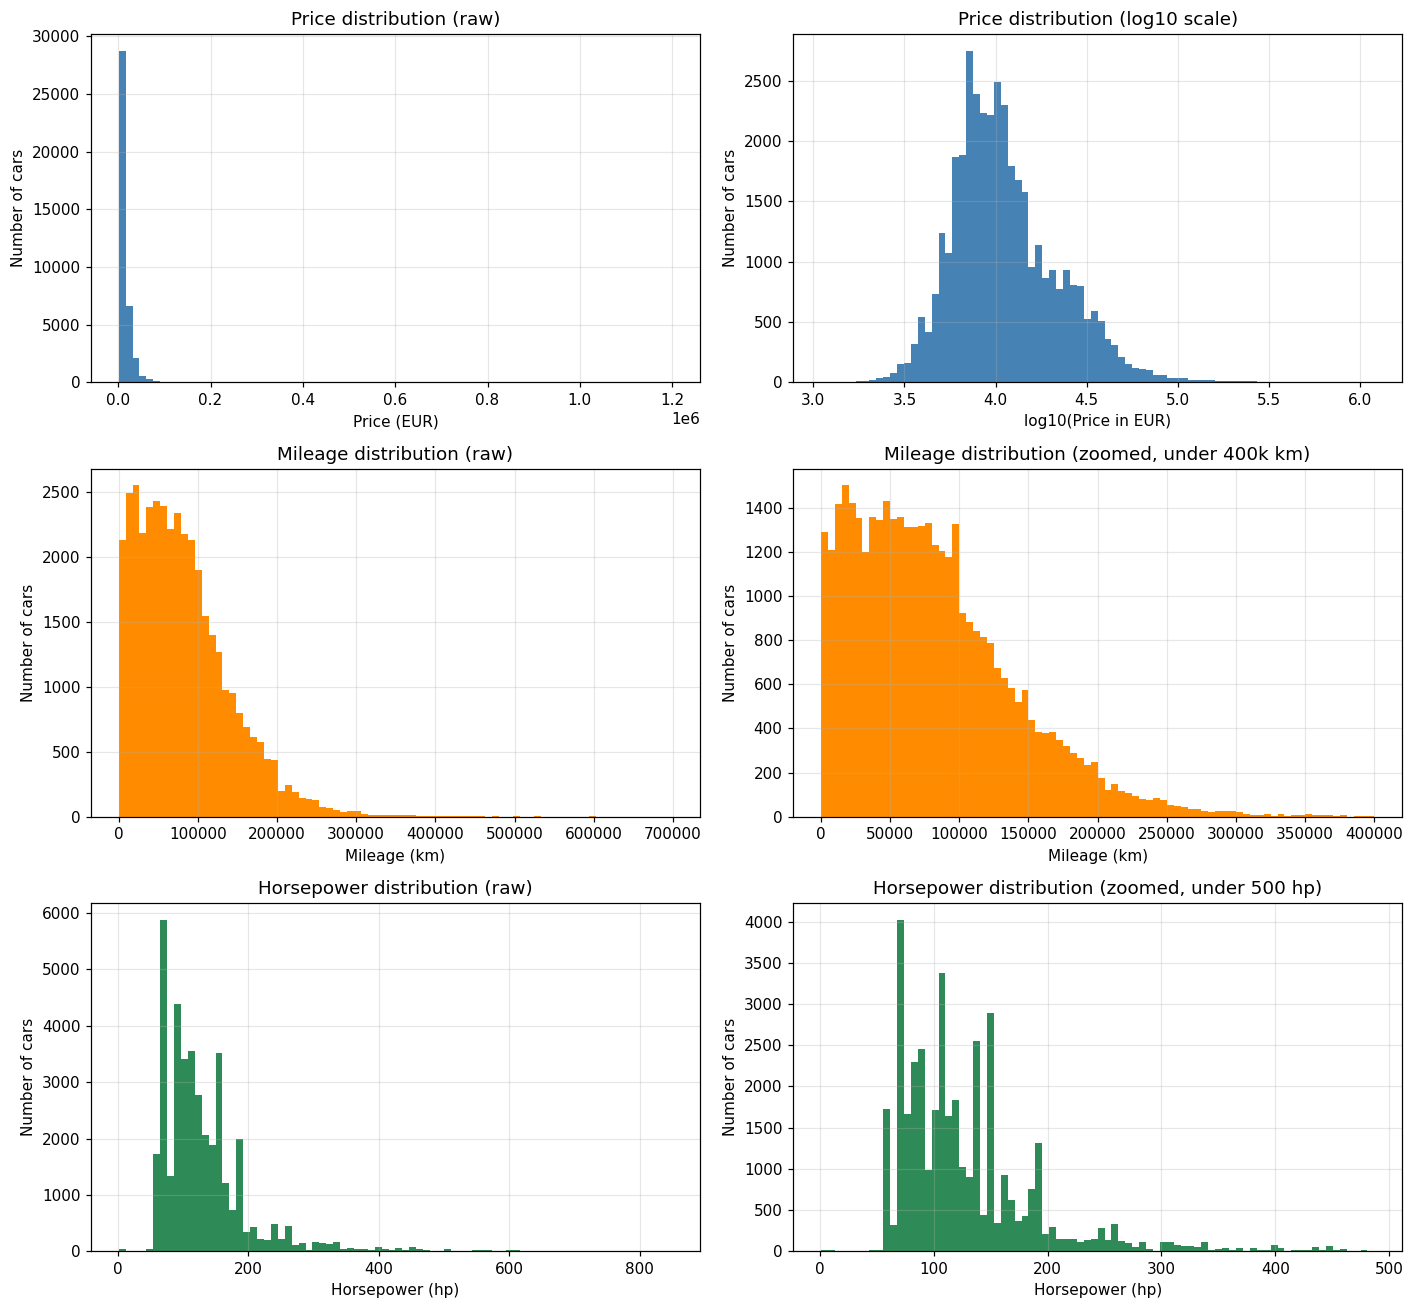

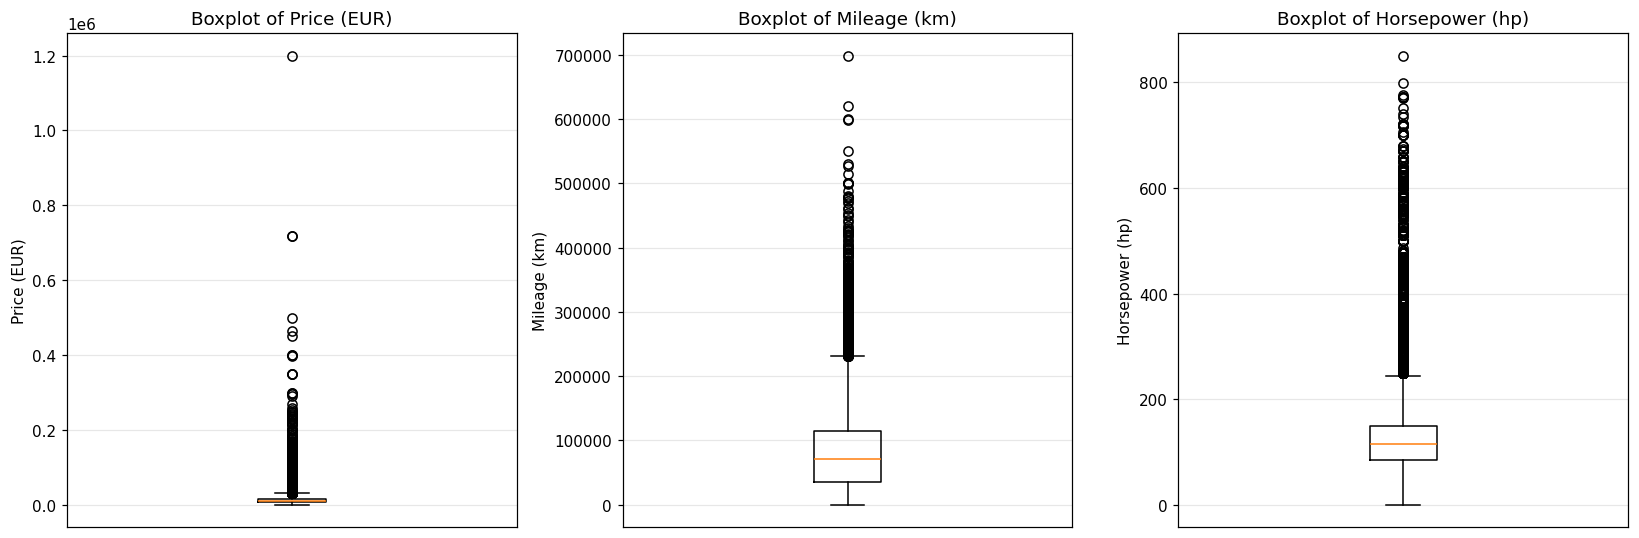

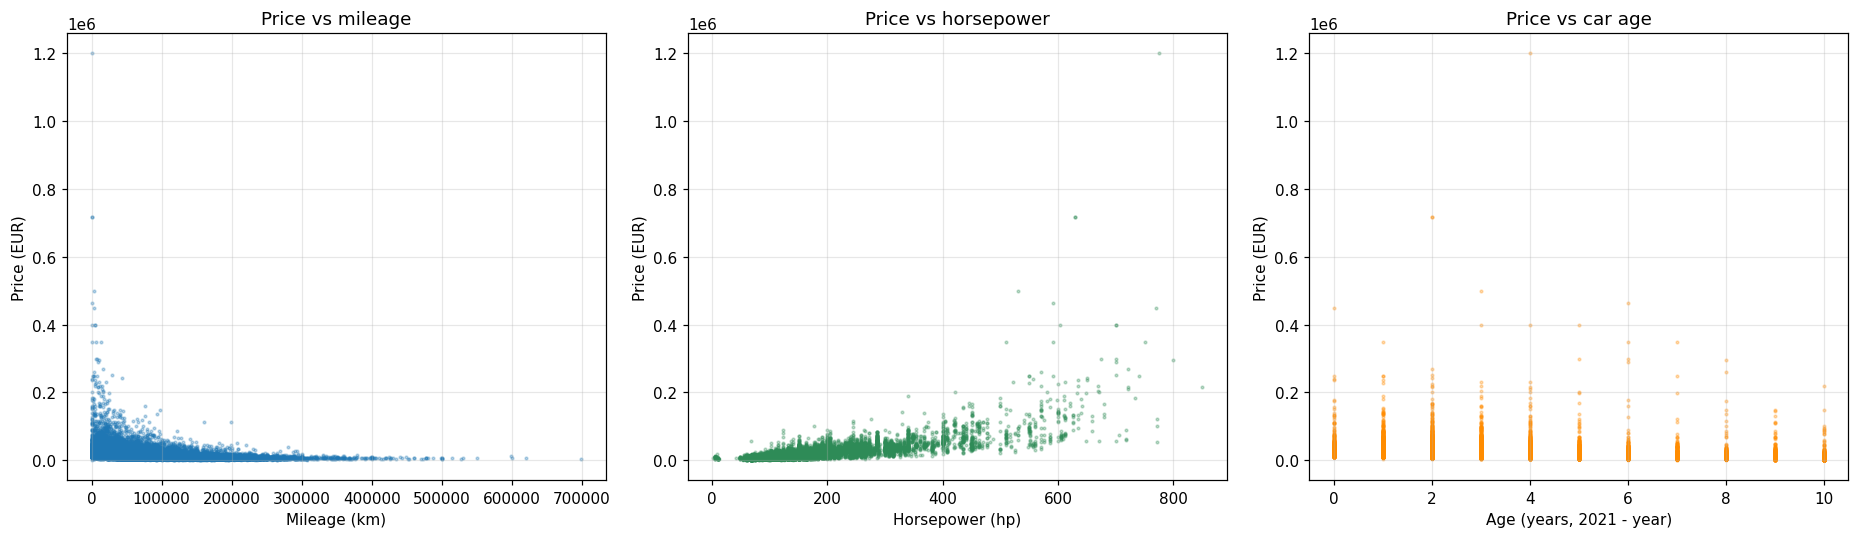

In [9]:
# Temporary frame with the derived columns so we can eyeball the extremes
eda = df1.assign(age=REF_YEAR - df1["year"], make_model=df1["make"] + " " + df1["model"])

# ---------- 1. Distributions: raw vs zoomed/log ----------
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
axes[0, 0].hist(eda["price"], bins=80, color="steelblue")
axes[0, 0].set(title="Price distribution (raw)", xlabel="Price (EUR)", ylabel="Number of cars")
axes[0, 1].hist(np.log10(eda["price"]), bins=80, color="steelblue")
axes[0, 1].set(title="Price distribution (log10 scale)", xlabel="log10(Price in EUR)", ylabel="Number of cars")
axes[1, 0].hist(eda["mileage"], bins=80, color="darkorange")
axes[1, 0].set(title="Mileage distribution (raw)", xlabel="Mileage (km)", ylabel="Number of cars")
axes[1, 1].hist(eda["mileage"][eda["mileage"] < 400_000], bins=80, color="darkorange")
axes[1, 1].set(title="Mileage distribution (zoomed, under 400k km)", xlabel="Mileage (km)", ylabel="Number of cars")
axes[2, 0].hist(eda["hp"], bins=80, color="seagreen")
axes[2, 0].set(title="Horsepower distribution (raw)", xlabel="Horsepower (hp)", ylabel="Number of cars")
axes[2, 1].hist(eda["hp"][eda["hp"] < 500], bins=80, color="seagreen")
axes[2, 1].set(title="Horsepower distribution (zoomed, under 500 hp)", xlabel="Horsepower (hp)", ylabel="Number of cars")
plt.tight_layout(); plt.show()

# ---------- 2. Boxplots: where the outlier points sit ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, label in zip(axes, ["price", "mileage", "hp"], ["Price (EUR)", "Mileage (km)", "Horsepower (hp)"]):
    ax.boxplot(eda[col], showfliers=True)
    ax.set(title=f"Boxplot of {label}", ylabel=label, xticks=[])
plt.tight_layout(); plt.show()

# ---------- 3. Scatter plots: outliers relative to the main relationships ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(eda["mileage"], eda["price"], s=3, alpha=0.3)
axes[0].set(title="Price vs mileage", xlabel="Mileage (km)", ylabel="Price (EUR)")
axes[1].scatter(eda["hp"], eda["price"], s=3, alpha=0.3, color="seagreen")
axes[1].set(title="Price vs horsepower", xlabel="Horsepower (hp)", ylabel="Price (EUR)")
axes[2].scatter(eda["age"], eda["price"], s=3, alpha=0.3, color="darkorange")
axes[2].set(title="Price vs car age", xlabel="Age (years, 2021 - year)", ylabel="Price (EUR)")
plt.tight_layout(); plt.show()

In [10]:
# ---------- Numbers used to choose the cutoffs ----------
print("ROWS:", len(eda), "\n")
pcts = [0.001, 0.005, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.995, 0.999]
print("PERCENTILES\n", eda[["price", "mileage", "hp", "age"]].quantile(pcts).round(0), "\n")

print("COUNTS BELOW/ABOVE CANDIDATE THRESHOLDS")
for label, n in [("hp < 30", (eda["hp"] < 30).sum()), ("hp < 50", (eda["hp"] < 50).sum()),
                 ("hp > 500", (eda["hp"] > 500).sum()),
                 ("mileage == 0", (eda["mileage"] == 0).sum()),
                 ("mileage > 300k", (eda["mileage"] > 300_000).sum()),
                 ("mileage > 500k", (eda["mileage"] > 500_000).sum()),
                 ("price < 2000", (eda["price"] < 2000).sum()),
                 ("price > 100k", (eda["price"] > 100_000).sum()),
                 ("age == 0", (eda["age"] == 0).sum())]:
    print(f"{label:<15}: {n}")

cols = ["make_model", "age", "mileage", "hp", "price"]
for title, frame in [("10 CHEAPEST", eda.nsmallest(10, "price")),
                     ("10 MOST EXPENSIVE", eda.nlargest(10, "price")),
                     ("10 HIGHEST MILEAGE", eda.nlargest(10, "mileage")),
                     ("10 LOWEST HP", eda.nsmallest(10, "hp")),
                     ("10 HIGHEST HP", eda.nlargest(10, "hp"))]:
    print(f"\n{title}\n", frame[cols].to_string())

print("\nRarest makes (look for non-car entries):")
print(eda["make"].value_counts().tail(30))

ROWS: 38553 

PERCENTILES
           price   mileage     hp   age
0.001    2181.0       5.0   48.0   0.0
0.005    2800.0      10.0   60.0   0.0
0.010    3200.0      50.0   60.0   0.0
0.050    4499.0    8000.0   67.0   1.0
0.250    6999.0   35850.0   86.0   3.0
0.500    9990.0   71557.0  116.0   6.0
0.750   16490.0  113979.0  150.0   8.0
0.950   37950.0  193000.0  258.0  10.0
0.990   71960.0  265000.0  435.0  10.0
0.995   98056.0  300000.0  530.0  10.0
0.999  199940.0  408439.0  640.0  10.0 

COUNTS BELOW/ABOVE CANDIDATE THRESHOLDS
hp < 30        : 35
hp < 50        : 54
hp > 500       : 229
mileage == 0   : 9
mileage > 300k : 185
mileage > 500k : 8
price < 2000   : 33
price > 100k   : 175
age == 0       : 537

10 CHEAPEST
               make_model  age  mileage     hp  price
23464         Citroen C1   10   204000   68.0   1100
17155        Lada Priora   10   100611   98.0   1190
23487        Toyota Aygo    9   153000   68.0   1250
17811        Peugeot 206   10   222000   68.0   1299
24

**Cutoffs chosen from the output above**

| Rule | Why |
|---|---|
| `hp < 30` | 1-hp "cars" are data errors; trailers and `Others` also show up here |
| `mileage == 0` | an exactly-0-km "used" car is almost certainly mislabeled |
| `mileage > 500,000` | includes the 999,999 placeholder; the rest are a few real vans, too sparse to model |
| `price > 100,000` | supercars (Ferrari, Lamborghini, Maybach) are a different market. 100k is near the 99.5th percentile (99,320). **Scope decision: this model targets the mainstream used market.** |
| non-car makes | `Others`, `Trailer-Anhänger`, `Caravans-Wohnm`, `Trucks-Lkw` |
| *kept:* cheap cars | a 1,100 EUR Citroen C1 is plausible |
| *kept:* `hp > 500` | after the price cap these are mostly Teslas / AMG / RS models and look real |

## 6. Cleaning, stage 2: outlier rules, then features

In [11]:
HP_MIN = 30
MILEAGE_MAX = 500_000
PRICE_MAX = 100_000
NON_CAR_MAKES = ["Caravans-Wohnm", "Trailer-Anhänger", "Trucks-Lkw", "Others"]

log2 = list(log1)           # continue the same log; log1 / df1 stay untouched so this cell can be re-run
df2 = df1

df2 = apply_filter(df2, log2, f"hp < {HP_MIN}", df2["hp"] >= HP_MIN)
df2 = apply_filter(df2, log2, "mileage == 0", df2["mileage"] > 0)
df2 = apply_filter(df2, log2, f"mileage > {MILEAGE_MAX:,}", df2["mileage"] <= MILEAGE_MAX)
df2 = apply_filter(df2, log2, f"price > {PRICE_MAX:,}", df2["price"] <= PRICE_MAX)
df2 = apply_filter(df2, log2, "non-car makes", ~df2["make"].isin(NON_CAR_MAKES))

# ---------- Features and target ----------
df = df2.copy()
df["age"] = REF_YEAR - df["year"]                      # more interpretable than raw year; collinear with it, so year is dropped
df["make_model"] = df["make"] + " " + df["model"]      # a model name only means something within its make
df["log_price"] = np.log(df["price"])                  # price is right-skewed; depreciation is roughly multiplicative
df = df.drop(columns=["offerType", "year"])            # offerType is now constant

display(log_table(log2))

# ---------- Sanity checks ----------
assert df.isna().sum().sum() == 0, "unexpected nulls left"
print("Duplicates left        :", df.duplicated().sum())
print("make_model unique      :", df["make_model"].nunique())
print("hp > 500 remaining     :", (df["hp"] > 500).sum())
print("Final rows             :", len(df), f"({len(df) / len(df_raw):.1%} of raw)")
display(df[["price", "mileage", "hp", "age"]].describe().round(0))

,step,removed,rows_after,% of raw
0,raw data,0,46405,100.0
1,exact duplicate rows,2140,44265,95.4
2,offerType != 'Used' (new / demo / pre-register...,5425,38840,83.7
3,missing model / gear / hp,287,38553,83.1
4,hp < 30,35,38518,83.0
5,mileage == 0,9,38509,83.0
6,"mileage > 500,000",8,38501,83.0
7,"price > 100,000",175,38326,82.6
8,non-car makes,1,38325,82.6


Duplicates left        : 0
make_model unique      : 769
hp > 500 remaining     : 121
Final rows             : 38325 (82.6% of raw)


,price,mileage,hp,age
count,38325.0,38325.0,38325.0,38325.0
mean,14010.0,81948.0,130.0,6.0
std,11595.0,59896.0,67.0,3.0
min,1100.0,1.0,41.0,0.0
25%,6999.0,36200.0,86.0,3.0
50%,9990.0,72000.0,116.0,6.0
75%,16250.0,114008.0,150.0,8.0
max,99999.0,500000.0,772.0,10.0


Expected on the Kaggle version used: **38,325 rows** (46,405 raw, 17.4% removed). Chain from the original run: duplicates 2,140, non-used offers 5,425, nulls 287, hp < 30: 35, mileage == 0: 9, mileage > 500k: 8, price > 100k: 175, non-cars: 1.

**Caveat for the write-up:** these cutoffs were chosen by looking at the full dataset *before* the split, so test rows had a tiny influence on cleaning decisions. They are coarse rules, not fitted parameters, so the effect should be negligible, but it is worth one sentence.

## 7. Train / test split

One split, fixed seed, done **before** any encoder or scaler exists. The test set stays closed until section 12.

In [12]:
X = df[FEATURES]
y = df["log_price"]        # training target
y_eur = df["price"]        # kept for reporting in EUR

X_train, X_test, y_train, y_test, y_train_eur, y_test_eur = train_test_split(
    X, y, y_eur, test_size=0.2, random_state=SEED)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Median price  train:", y_train_eur.median(), " test:", y_test_eur.median())

Train: (30660, 7)  Test: (7665, 7)
Median price  train: 9990.0  test: 9990.0


## 8. Preprocessing and the `min_frequency` experiment

Rare `make_model` values (a few listings each) cannot be learned reliably, so the encoder groups them into an "infrequent" bucket. The threshold is computed **inside** each training fold because the encoder sits inside the pipeline. `make` is a separate feature, so a grouped rare model still keeps its brand.

In [13]:
# Same folds for every model, otherwise the comparison is unfair
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def make_preprocessor(scale, min_frequency=MIN_FREQ):
    """Linear models need scaled numerics; tree models do not."""
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUM_COLS),
        ("cat", OneHotEncoder(min_frequency=min_frequency, handle_unknown="infrequent_if_exist"), CAT_COLS),
    ])

# How much of the TRAINING data falls into the "infrequent" bucket at each threshold?
counts = X_train["make_model"].value_counts()
for t in [2, 3, 5, 10, 20]:
    rare = counts[counts < t].index
    print(f"min_frequency={t:>2}: {(counts >= t).sum():>3} categories kept, "
          f"{X_train['make_model'].isin(rare).mean():.1%} of train rows infrequent")

min_frequency= 2: 618 categories kept, 0.4% of train rows infrequent
min_frequency= 3: 543 categories kept, 0.9% of train rows infrequent
min_frequency= 5: 461 categories kept, 1.8% of train rows infrequent
min_frequency=10: 344 categories kept, 4.3% of train rows infrequent
min_frequency=20: 244 categories kept, 9.0% of train rows infrequent


In [14]:
# Experiment: does the threshold matter? (Ridge, 5-fold CV, train set only)
for t in [2, 3, 5, 10, 20]:
    pipe = Pipeline([("pre", make_preprocessor(True, min_frequency=t)), ("m", Ridge(alpha=1.0))])
    s = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"min_frequency={t:>2}: RMSE (log price) = {-s.mean():.4f} ± {s.std():.4f}")

min_frequency= 2: RMSE (log price) = 0.1520 ± 0.0023
min_frequency= 3: RMSE (log price) = 0.1532 ± 0.0025
min_frequency= 5: RMSE (log price) = 0.1555 ± 0.0029
min_frequency=10: RMSE (log price) = 0.1592 ± 0.0030
min_frequency=20: RMSE (log price) = 0.1656 ± 0.0037


**Finding (original run):** lower thresholds score *better* on Ridge, monotonically: 0.1520 at 2, 0.1532 at 3, 0.1555 at 5, 0.1592 at 10, 0.1656 at 20. 2 vs 3 vs 5 differ by less than about one std (0.0025), so they are effectively tied; 10 and 20 are clearly worse. I expected a *higher* threshold to help the linear model, and it did not.
**Decision:** `MIN_FREQ = 3`, used for every model.

## 9. Baselines and model comparison

In [15]:
# ---------- Sanity floor: does the data carry signal at all? ----------
dummy = cross_val_score(DummyRegressor(strategy="median"), X_train, y_train, cv=kf,
                        scoring="neg_root_mean_squared_error")
print(f"Dummy (always predict the median) RMSE (log): {-dummy.mean():.4f} ± {dummy.std():.4f}")
display(df[["price", "age", "mileage", "hp"]].corr(method="spearman").round(2))

Dummy (always predict the median) RMSE (log): 0.6509 ± 0.0091


,price,age,mileage,hp
price,1.00,-0.66,-0.44,0.69
age,-0.66,1.00,0.67,-0.15
mileage,-0.44,0.67,1.00,0.10
hp,0.69,-0.15,0.10,1.00


In [16]:
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

models = {
    "Linear": Pipeline([("pre", make_preprocessor(True)), ("m", LinearRegression())]),
    "Ridge": Pipeline([("pre", make_preprocessor(True)), ("m", Ridge(alpha=1.0))]),
    # Untuned sklearn defaults apart from 200 trees (max_features = all columns, fully grown trees)
    "RandomForest": Pipeline([("pre", make_preprocessor(False)),
                              ("m", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED))]),
    "XGBoost": Pipeline([("pre", make_preprocessor(False)),
                         ("m", XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                                            tree_method="hist", n_jobs=-1, random_state=SEED))]),
}
FAST_MODELS = ["Linear", "Ridge", "XGBoost"]

def make_catboost():
    # Handles categoricals natively, so it needs no one-hot step and no min_frequency
    return CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6,
                             cat_features=CAT_COLS, verbose=0, random_seed=SEED)

def catboost_cv(X, y, cv):
    """CatBoost cannot go through sklearn's cross_validate (clone() fails because CatBoost rewrites
    its cat_features parameter), so loop over the SAME folds by hand."""
    out = {"train_rmse": [], "val_rmse": [], "val_mae": [], "fit_time": []}
    for tr, va in cv.split(X):
        m = make_catboost()
        t0 = time.time()
        m.fit(X.iloc[tr], y.iloc[tr])
        out["fit_time"].append(time.time() - t0)
        out["train_rmse"].append(rmse(y.iloc[tr], m.predict(X.iloc[tr])))
        pred = m.predict(X.iloc[va])
        out["val_rmse"].append(rmse(y.iloc[va], pred))
        out["val_mae"].append(mean_absolute_error(y.iloc[va], pred))
    return out

rows = []   # one row per model; sorted into the results table below

In [17]:
# Linear, Ridge, XGBoost (fast)
for name in FAST_MODELS:
    r = cross_validate(models[name], X_train, y_train, cv=kf, n_jobs=1, scoring=SCORING)
    rows.append({"model": name, "RMSE (log)": -r["test_rmse"].mean(), "± RMSE": r["test_rmse"].std(),
                 "MAE (log)": -r["test_mae"].mean(), "fit time (s)": r["fit_time"].mean()})
    print(name, "done")

# CatBoost (kept so the bias/variance section can reuse its train scores)
cb = catboost_cv(X_train, y_train, kf)
rows.append({"model": "CatBoost", "RMSE (log)": np.mean(cb["val_rmse"]), "± RMSE": np.std(cb["val_rmse"]),
             "MAE (log)": np.mean(cb["val_mae"]), "fit time (s)": np.mean(cb["fit_time"])})
print("CatBoost done")

Linear done
Ridge done
XGBoost done
CatBoost done


In [18]:
# Random Forest (SLOW: about 4 min per fit in the original run, about 20 min in total)
if RUN_RANDOM_FOREST:
    r = cross_validate(models["RandomForest"], X_train, y_train, cv=kf, n_jobs=1, scoring=SCORING)
    rows.append({"model": "RandomForest", "RMSE (log)": -r["test_rmse"].mean(), "± RMSE": r["test_rmse"].std(),
                 "MAE (log)": -r["test_mae"].mean(), "fit time (s)": r["fit_time"].mean()})
    print("RandomForest done")
else:
    print("RandomForest skipped (RUN_RANDOM_FOREST = False)")

RandomForest done


In [19]:
results = pd.DataFrame(rows).sort_values("RMSE (log)").round(4)
display(results.reset_index(drop=True))

,model,RMSE (log),± RMSE,MAE (log),fit time (s)
0,Linear,0.1529,0.0022,0.1126,0.6657
1,Ridge,0.1532,0.0025,0.1127,0.2643
2,CatBoost,0.1544,0.0033,0.1135,11.3504
3,XGBoost,0.1573,0.0030,0.1167,2.5557
4,RandomForest,0.1664,0.0036,0.1210,246.4314


**Original run (5-fold CV on the training set, log-price RMSE):**

| model | RMSE (log) | ± | fit time per fold |
|---|---|---|---|
| Linear | 0.1529 | 0.0022 | 1.2 s |
| Ridge | 0.1532 | 0.0025 | 0.9 s |
| CatBoost | 0.1544 | 0.0033 | 11.4 s |
| XGBoost (untuned) | 0.1573 | 0.0030 | 2.4 s |
| RandomForest (untuned) | 0.1664 | 0.0036 | 239 s |

Linear, Ridge and CatBoost are tied within noise. XGBoost is slightly behind before tuning. Random Forest is last and about 200x slower. That Random Forest ran with plain sklearn defaults (all columns considered at every split, fully grown trees); *why* it trails is untested, so do not claim a reason in the write-up. A log-RMSE of about 0.153 means typical errors of roughly 15%.

## 10. Bias / variance diagnostics

Bias and variance describe a *model on a dataset*. Two checks: (1) training error vs CV error, (2) learning curves (does more data help?).

In [20]:
# ---------- 1. Train vs CV error ----------
gap_rows = []
for name in FAST_MODELS:
    r = cross_validate(models[name], X_train, y_train, cv=kf,
                       scoring="neg_root_mean_squared_error", return_train_score=True)
    gap_rows.append({"model": name, "train RMSE": -r["train_score"].mean(), "CV RMSE": -r["test_score"].mean()})
gap_rows.append({"model": "CatBoost", "train RMSE": np.mean(cb["train_rmse"]), "CV RMSE": np.mean(cb["val_rmse"])})

gap = pd.DataFrame(gap_rows)
gap["gap (CV - train)"] = gap["CV RMSE"] - gap["train RMSE"]
display(gap.round(4))

,model,train RMSE,CV RMSE,gap (CV - train)
0,Linear,0.1467,0.1529,0.0061
1,Ridge,0.1478,0.1532,0.0054
2,XGBoost,0.1401,0.1573,0.0171
3,CatBoost,0.1489,0.1544,0.0054


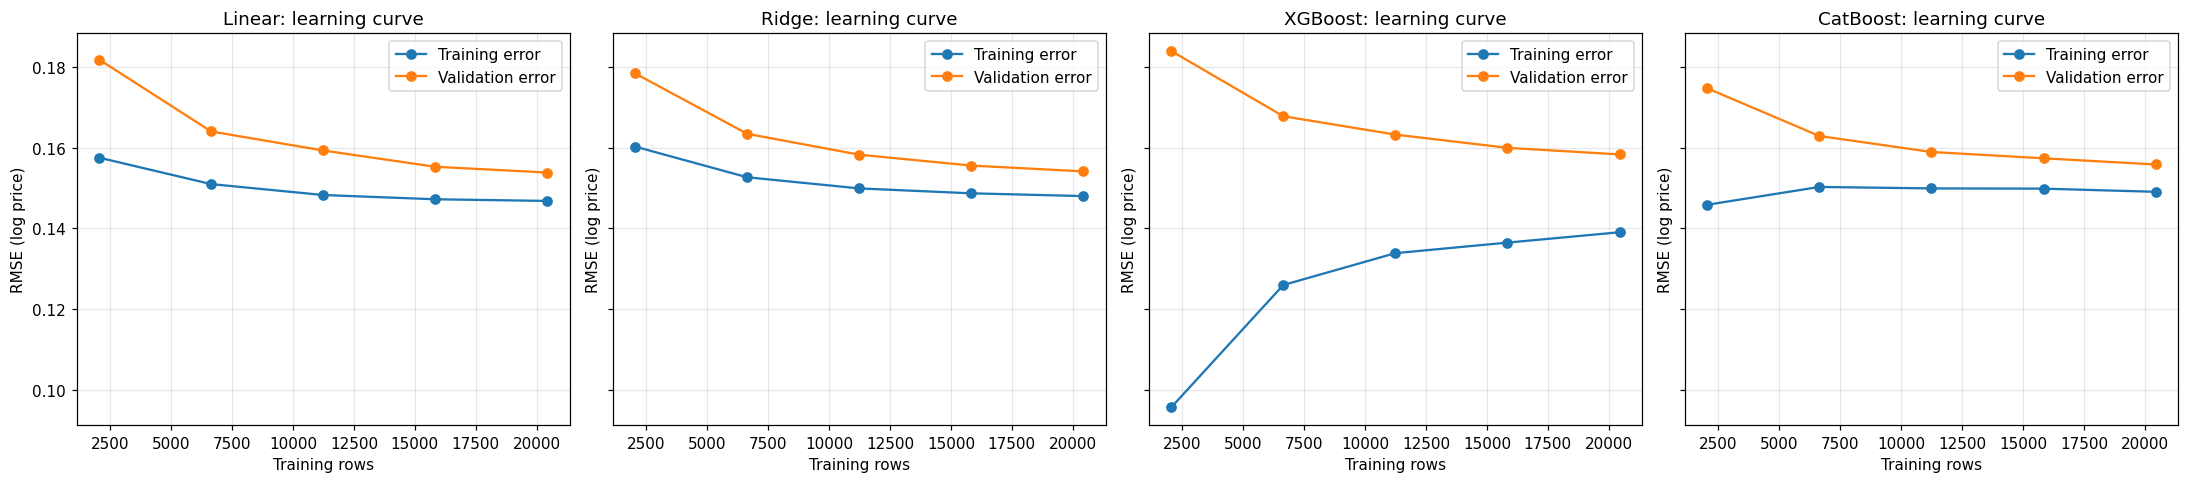

,rows,train,val
0,2044,0.1459,0.1748
1,6643,0.1503,0.1629
2,11242,0.1499,0.1590
3,15841,0.1499,0.1574
4,20440,0.1491,0.1559


In [21]:
# ---------- 2. Learning curves ----------
# X_train is already randomly shuffled by train_test_split, so "the first n rows" is a random subset.
if RUN_LEARNING_CURVES:
    kf3 = KFold(n_splits=3, shuffle=True, random_state=SEED)
    fractions = np.linspace(0.1, 1.0, 5)

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
    for ax, name in zip(axes[:3], FAST_MODELS):
        n, tr, va = learning_curve(models[name], X_train, y_train, cv=kf3, train_sizes=fractions,
                                   scoring="neg_root_mean_squared_error", n_jobs=1)
        ax.plot(n, -tr.mean(1), "o-", label="Training error")
        ax.plot(n, -va.mean(1), "o-", label="Validation error")
        ax.set(title=f"{name}: learning curve", xlabel="Training rows", ylabel="RMSE (log price)")
        ax.legend()

    # CatBoost by hand (same reason as catboost_cv)
    cb_rows = []
    for frac in fractions:
        tr_e, va_e, n_used = [], [], []
        for tr, va in kf3.split(X_train):
            idx = tr[: int(len(tr) * frac)]
            m = make_catboost()
            m.fit(X_train.iloc[idx], y_train.iloc[idx])
            tr_e.append(rmse(y_train.iloc[idx], m.predict(X_train.iloc[idx])))
            va_e.append(rmse(y_train.iloc[va], m.predict(X_train.iloc[va])))
            n_used.append(len(idx))
        cb_rows.append({"rows": int(np.mean(n_used)), "train": np.mean(tr_e), "val": np.mean(va_e)})
    cb_curve = pd.DataFrame(cb_rows)
    axes[3].plot(cb_curve["rows"], cb_curve["train"], "o-", label="Training error")
    axes[3].plot(cb_curve["rows"], cb_curve["val"], "o-", label="Validation error")
    axes[3].set(title="CatBoost: learning curve", xlabel="Training rows", ylabel="RMSE (log price)")
    axes[3].legend()
    plt.tight_layout(); plt.show()
    display(cb_curve.round(4))
else:
    print("Learning curves skipped (RUN_LEARNING_CURVES = False)")

**Findings (original run)**
- Train RMSE is about 0.14-0.15 for *every* model, even the flexible ones. The error floor comes from the 7 features and the noise in asking prices, not from overfitting.
- Gaps (CV minus train): Linear 0.0061, Ridge 0.0054, CatBoost 0.0054, **XGBoost 0.0171**. Only XGBoost shows visible overfitting.
- CatBoost's validation error keeps falling but flattens (0.1748 at 2,044 rows to 0.1559 at 20,440): more rows would help only a little. The features are the limit, not the data size.
- The gap is a diagnostic, not a target. Minimize CV error; use the gap only to decide which direction to tune.

## 11. Hyperparameter experiments

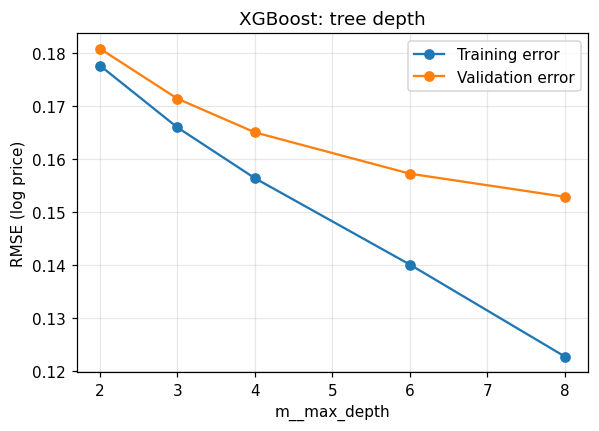

,m__max_depth,train,val
0,2,0.1777,0.1809
1,3,0.1660,0.1714
2,4,0.1564,0.1651
3,6,0.1401,0.1573
4,8,0.1228,0.1529


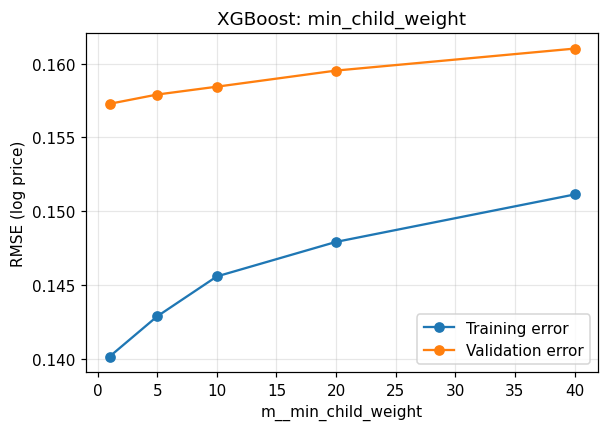

,m__min_child_weight,train,val
0,1,0.1401,0.1573
1,5,0.1429,0.1579
2,10,0.1456,0.1584
3,20,0.1479,0.1595
4,40,0.1511,0.1610


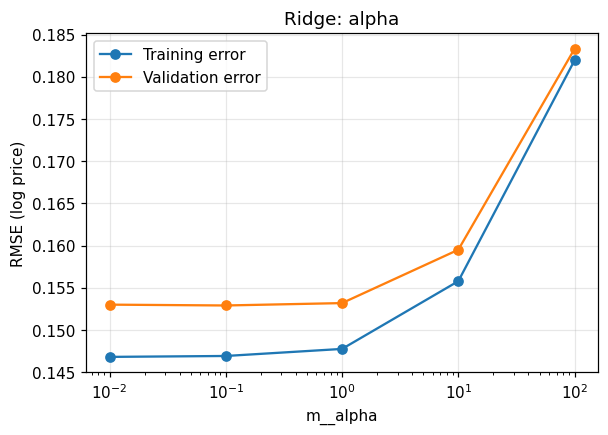

,m__alpha,train,val
0,0.01,0.1468,0.1530
1,0.10,0.1469,0.1529
2,1.00,0.1478,0.1532
3,10.00,0.1558,0.1595
4,100.00,0.1819,0.1833


In [22]:
def vcurve(pipe, param, values, title, log=False):
    """Validation curve: train vs CV error as one hyperparameter varies (5-fold CV, train set)."""
    tr, va = validation_curve(pipe, X_train, y_train, param_name=param, param_range=values, cv=kf,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
    plt.figure(figsize=(6, 4))
    plt.plot(values, -tr.mean(1), "o-", label="Training error")
    plt.plot(values, -va.mean(1), "o-", label="Validation error")
    if log: plt.xscale("log")
    plt.title(title); plt.xlabel(param); plt.ylabel("RMSE (log price)")
    plt.legend(); plt.show()
    display(pd.DataFrame({param: values, "train": -tr.mean(1), "val": -va.mean(1)}).round(4))

vcurve(models["XGBoost"], "m__max_depth", [2, 3, 4, 6, 8], "XGBoost: tree depth")
vcurve(models["XGBoost"], "m__min_child_weight", [1, 5, 10, 20, 40], "XGBoost: min_child_weight")
vcurve(models["Ridge"], "m__alpha", [0.01, 0.1, 1, 10, 100], "Ridge: alpha", log=True)

**Findings (original run)** — these contradicted my initial expectation that shallower trees would help:
- XGBoost validation error *falls* as depth grows (0.1809 at depth 2 to 0.1529 at depth 8) even though the train/validation gap widens. Deeper is better here.
- `min_child_weight = 1` (least regularized) is best.
- Ridge `alpha` from 0.01 to 1 gives the same score as plain Linear (0.1529-0.1532). Ridge has nothing left to give.

In [23]:
# ---------- Search v1: DEAD END, kept on purpose ----------
# The depth range randint(2, 8) = 2..7 never reached the good region found by the validation curve above.
if RUN_SEARCH_V1:
    search1 = RandomizedSearchCV(
        models["XGBoost"],
        param_distributions={
            "m__max_depth": randint(2, 8),
            "m__min_child_weight": randint(1, 40),
            "m__subsample": uniform(0.6, 0.4),
            "m__colsample_bytree": uniform(0.5, 0.5),
            "m__reg_lambda": uniform(0.5, 20),
            "m__learning_rate": uniform(0.02, 0.1),
            "m__n_estimators": randint(200, 800),
        },
        n_iter=25, cv=kf, scoring="neg_root_mean_squared_error",
        n_jobs=1, random_state=SEED, return_train_score=True)
    search1.fit(X_train, y_train)
    print("Search v1 best CV RMSE:", -search1.best_score_)
    print(search1.best_params_)
else:
    print("Search v1 skipped (RUN_SEARCH_V1 = False)")

Search v1 best CV RMSE: 0.15445991098753709
{'m__colsample_bytree': np.float64(0.5740434649766999), 'm__learning_rate': np.float64(0.11977404850489419), 'm__max_depth': 4, 'm__min_child_weight': 2, 'm__n_estimators': 419, 'm__reg_lambda': np.float64(1.529575024999787), 'm__subsample': np.float64(0.7114585856946446)}


**Search v1 result (original run):** best CV RMSE 0.1545 at depth 4: no better than untuned XGBoost, because the search space excluded the region the validation curve pointed to (deeper trees). 25 random draws over 7 parameters is also a thin search.

In [25]:
# ---------- Search v2: depth range moved to 7-12 ----------
search2 = RandomizedSearchCV(
    models["XGBoost"],
    param_distributions={
        "m__max_depth": randint(7, 13),               # 7-12
        "m__min_child_weight": randint(1, 8),
        "m__learning_rate": uniform(0.03, 0.09),      # 0.03-0.12
        "m__n_estimators": randint(300, 900),
        "m__subsample": uniform(0.6, 0.4),
        "m__colsample_bytree": uniform(0.5, 0.5),
        "m__reg_lambda": uniform(0.5, 10),
    },
    n_iter=15, cv=kf, scoring="neg_root_mean_squared_error",
    n_jobs=1, random_state=SEED, return_train_score=True)   # refit=True (default): best model is refit on all of X_train
search2.fit(X_train, y_train)

res = pd.DataFrame(search2.cv_results_)
res["train_rmse"] = -res["mean_train_score"]
res["val_rmse"] = -res["mean_test_score"]
res["gap"] = res["val_rmse"] - res["train_rmse"]
print("Search v2 best CV RMSE:", -search2.best_score_)
print(search2.best_params_)
display(res.nsmallest(5, "rank_test_score")[["train_rmse", "val_rmse", "std_test_score", "gap"]].round(4))

Search v2 best CV RMSE: 0.1443473175741369
{'m__colsample_bytree': np.float64(0.6912309956335814), 'm__learning_rate': np.float64(0.11849077972261093), 'm__max_depth': 7, 'm__min_child_weight': 3, 'm__n_estimators': 784, 'm__reg_lambda': np.float64(6.575448519014383), 'm__subsample': np.float64(0.6682096494749166)}


,train_rmse,val_rmse,std_test_score,gap
4,0.1179,0.1443,0.0030,0.0264
2,0.1119,0.1444,0.0032,0.0326
1,0.1154,0.1444,0.0027,0.0291
8,0.1163,0.1446,0.0028,0.0283
14,0.0912,0.1456,0.0033,0.0544


**Search v2 result (original run):** best CV RMSE **0.1443** (depth 7, 784 trees, `reg_lambda` about 6.6, subsample about 0.67) against **0.1529** for Linear. That is a gap of 0.0086, roughly three times the CV noise and past the 0.003 winner rule set beforehand. The top four configurations are within noise of each other (0.1443-0.1446), so the exact winning parameters are not special.

The win comes from a *combination*: deep trees plus row/column subsampling and L2 regularization. Plausible reason (untested): depreciation curves differ per make/model, and deep trees can capture that interaction where a linear model cannot.

**Fairness note for the write-up:** XGBoost got a tuning round and Ridge got an alpha check; CatBoost and Random Forest ran near defaults. The 0.1443 is also the best of 15 configurations picked on the same folds that scored it, so it is slightly optimistic. The test set (next section) is the honest number.

## 12. Final test evaluation — RUN ONCE

The 20% test set was never used for fitting, tuning or model selection. Score the chosen model here, report the numbers, and **do not go back and change anything** based on them; otherwise the test set has quietly become a validation set.

In [26]:
def eval_eur(y_true_eur, pred_eur, y_true_log):
    """Metrics in EUR (what a reader can interpret) plus log-RMSE (comparable with the CV numbers)."""
    return {"RMSE (EUR)": rmse(y_true_eur, pred_eur),
            "MAE (EUR)": mean_absolute_error(y_true_eur, pred_eur),
            "MAPE (%)": float(np.mean(np.abs(y_true_eur - pred_eur) / y_true_eur) * 100),
            "R2": r2_score(y_true_eur, pred_eur),
            "log-RMSE": rmse(y_true_log, np.log(pred_eur))}

best = search2.best_estimator_                      # tuned XGBoost, already refit on all of X_train
pred_xgb = np.exp(best.predict(X_test))             # models predict log(price); exp() gives EUR

linear = clone(models["Linear"]).fit(X_train, y_train)   # for the report table only; selection is already done
pred_lin = np.exp(linear.predict(X_test))

test_report = pd.DataFrame({"XGBoost (tuned)": eval_eur(y_test_eur, pred_xgb, y_test),
                            "Linear": eval_eur(y_test_eur, pred_lin, y_test)}).T
display(test_report.round({"RMSE (EUR)": 0, "MAE (EUR)": 0, "MAPE (%)": 1, "R2": 3, "log-RMSE": 4}))

# Error by TRUE price band (see section 13 for why this view is misleading at the extremes)
bands = pd.cut(y_test_eur, [0, 5000, 10000, 20000, 40000, 100000])
err = pd.DataFrame({"band": bands, "abs_err": np.abs(y_test_eur - pred_xgb),
                    "pct_err": np.abs(y_test_eur - pred_xgb) / y_test_eur * 100})
display(err.groupby("band", observed=True).agg(n=("abs_err", "size"), MAE_EUR=("abs_err", "mean"),
                                              MAPE_pct=("pct_err", "mean")).round(1))

,RMSE (EUR),MAE (EUR),MAPE (%),R2,log-RMSE
XGBoost (tuned),2745.0,1456.0,10.5,0.945,0.1416
Linear,3033.0,1591.0,11.3,0.933,0.1492


,n,MAE_EUR,MAPE_pct
band,,,
"(0, 5000]",645,655.4,16.9
"(5000, 10000]",3290,750.5,9.9
"(10000, 20000]",2316,1367.1,9.8
"(20000, 40000]",1127,2626.6,9.2
"(40000, 100000]",287,7463.7,12.9


**Test result (original run):** tuned XGBoost log-RMSE 0.1416, RMSE 2,745 EUR, MAE 1,456 EUR, MAPE 10.5%, R2 0.945. Linear: log-RMSE 0.1492, RMSE 3,033 EUR, MAE 1,591 EUR.
The test score came out slightly *better* than CV (0.1416 vs 0.1443), and Linear shifted the same way (0.1492 vs 0.1529), so this test split is slightly easier than the average fold. The gap between the two models stayed about the same (0.0076 vs 0.0086), which is the consistency check that matters. In euros, XGBoost beats Linear by about 9% on RMSE and 8% on MAE: a real but modest gain.

R2 is computed in euros and is dominated by expensive cars; MAE and MAPE are the more honest summary (a typical prediction is off by about 1,500 EUR, or about 10%).

## 13. Residual analysis (descriptive only — do not tune on this)

Residual = `log(actual) - log(predicted)`; positive means underpredicted.

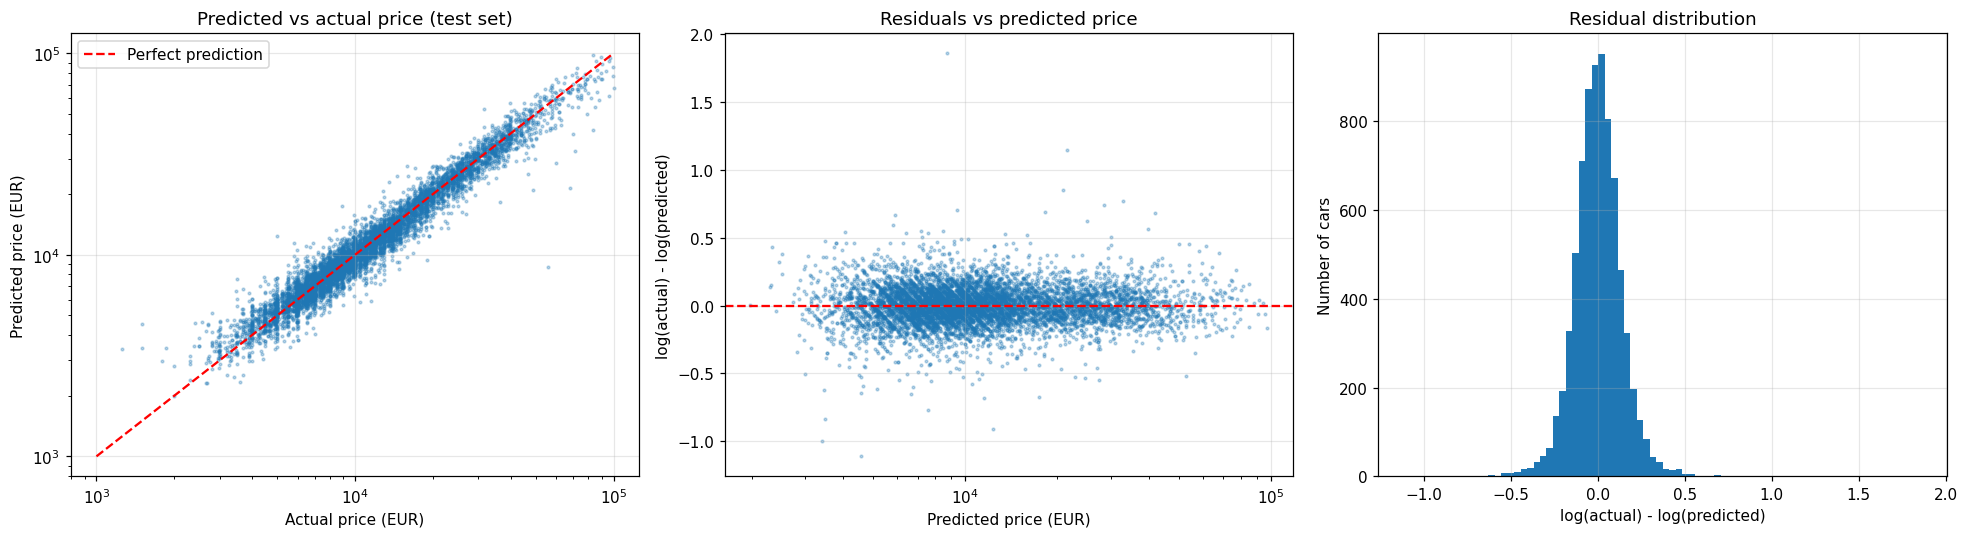

Mean log-residual by TRUE price band:


,size,mean
true,,
"(0, 5000]",645,-0.094
"(5000, 10000]",3290,-0.009
"(10000, 20000]",2316,0.027
"(20000, 40000]",1127,0.016
"(40000, 100000]",287,0.088


Mean log-residual by PREDICTED price band:


,size,mean
pred,,
"(0, 5000]",495,-0.001
"(5000, 10000]",3359,0.001
"(10000, 20000]",2350,0.002
"(20000, 40000]",1174,0.005
"(40000, 100000]",287,0.004


Worst makes by mean absolute log error:


,n,bias,mae
make,,,
Mercedes-Benz,399,0.012,0.123
Nissan,137,-0.015,0.120
Suzuki,63,-0.022,0.115
Citroen,168,-0.012,0.114
BMW,451,0.004,0.114
Peugeot,221,0.003,0.113
Mitsubishi,65,0.013,0.108
Hyundai,267,0.009,0.105


By car age:


,n,bias,mae
age,,,
0,102,-0.015,0.110
1,392,0.009,0.082
2,711,0.005,0.089
3,840,0.004,0.092
4,822,0.006,0.091
5,771,-0.002,0.093
6,843,0.002,0.100
7,809,-0.002,0.111
8,799,-0.002,0.112


In [27]:
res_df = X_test.copy()
res_df["true"], res_df["pred"] = y_test_eur, pred_xgb
res_df["resid"] = np.log(res_df["true"]) - np.log(res_df["pred"])

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(res_df["true"], res_df["pred"], s=3, alpha=0.3)
ax[0].plot([1000, 100000], [1000, 100000], "r--", label="Perfect prediction")
ax[0].set(xscale="log", yscale="log", title="Predicted vs actual price (test set)",
          xlabel="Actual price (EUR)", ylabel="Predicted price (EUR)")
ax[0].legend()
ax[1].scatter(res_df["pred"], res_df["resid"], s=3, alpha=0.3)
ax[1].axhline(0, color="r", ls="--")
ax[1].set(xscale="log", title="Residuals vs predicted price",
          xlabel="Predicted price (EUR)", ylabel="log(actual) - log(predicted)")
ax[2].hist(res_df["resid"], bins=80)
ax[2].set(title="Residual distribution", xlabel="log(actual) - log(predicted)", ylabel="Number of cars")
plt.tight_layout(); plt.show()

# Signed bias by band: grouping by TRUE price exaggerates the pattern (selection effect); grouping by PREDICTED price is the fair view
edges = [0, 5000, 10000, 20000, 40000, 100000]
print("Mean log-residual by TRUE price band:")
display(res_df.groupby(pd.cut(res_df["true"], edges), observed=True)["resid"].agg(["size", "mean"]).round(3))
print("Mean log-residual by PREDICTED price band:")
display(res_df.groupby(pd.cut(res_df["pred"], edges), observed=True)["resid"].agg(["size", "mean"]).round(3))

# Worst makes (at least 50 test rows) and error by car age
by_make = res_df.groupby("make")["resid"].agg(n="size", bias="mean", mae=lambda s: s.abs().mean())
print("Worst makes by mean absolute log error:")
display(by_make[by_make["n"] >= 50].nlargest(8, "mae").round(3))
print("By car age:")
display(res_df.groupby("age")["resid"].agg(n="size", bias="mean", mae=lambda s: s.abs().mean()).round(3))

**Findings (original run)**
- The model is well calibrated: grouped by *predicted* price, mean residual is within ±0.005 in every band. The apparent bias when grouping by *true* price (-0.094 for the cheapest band, +0.088 for the most expensive) is a selection artifact, not model bias.
- Cheap cars have the highest percentage error (16.9% MAPE) mostly because small euro errors are large relative to a small price.
- No make is a failure case: bias within ±0.022 for the worst eight, mean absolute log error between 0.105 and 0.123 (Mercedes-Benz and BMW at the top).
- Error grows with age: about 0.082 at age 1 to 0.137 at age 10, with bias near zero. Plausible reasons (untested): condition and history differ more in older cars, and the data has no trim or condition column.

## 14. Refit on all data and export for deployment

The model choice and the honest test score are finished. For deployment, refit the same configuration on train + test (more data helps). **Do not report test metrics for this refit model**; it has seen the test rows.

In [28]:
# clone() matters: fitting search2.best_estimator_ in place would silently contaminate `best`,
# and re-running the test evaluation above would then report leaked scores.
final = clone(search2.best_estimator_)
final.fit(pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))

# Guard: the honest model must be untouched by the refit
assert np.allclose(np.exp(best.predict(X_test)), pred_xgb), "best_estimator_ was modified by the refit"

joblib.dump(final, "car_price_model.joblib")

# Metadata the app needs to restrict inputs to what the model has seen
meta = {
    "reference_year": REF_YEAR,
    "makes": {mk: sorted(g["model"].unique().tolist()) for mk, g in df.groupby("make")},
    "fuel": sorted(df["fuel"].unique().tolist()),
    "gear": sorted(df["gear"].unique().tolist()),
    "mileage_range": [int(df["mileage"].min()), int(df["mileage"].max())],
    "hp_range": [int(df["hp"].min()), int(df["hp"].max())],
    "year_range": [int(REF_YEAR - df["age"].max()), REF_YEAR],
}
with open("meta.json", "w") as f:
    json.dump(meta, f)

# Sanity check: the saved file reloads and predicts sensibly (these rows were seen in the refit, so expect a close match)
reloaded = joblib.load("car_price_model.joblib")
check = X_test.head(3)
print("predicted:", np.exp(reloaded.predict(check)).round(0), "| actual:", y_test_eur.head(3).values)
print({k: (v if k != "makes" else f"{len(v)} makes") for k, v in meta.items()})

predicted: [ 5371. 28241. 10942.] | actual: [ 5999 27960 10500]
{'reference_year': 2021, 'makes': '60 makes', 'fuel': ['-/- (Fuel)', 'CNG', 'Diesel', 'Electric', 'Electric/Diesel', 'Electric/Gasoline', 'Ethanol', 'Gasoline', 'Hydrogen', 'LPG', 'Others'], 'gear': ['Automatic', 'Manual', 'Semi-automatic'], 'mileage_range': [1, 500000], 'hp_range': [41, 772], 'year_range': [2011, 2021]}


In [32]:
# Exact library versions for the app's requirements.txt (a joblib file can break across versions)
import sklearn, xgboost
print(f"scikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}\n"
      f"pandas=={pd.__version__}\nnumpy=={np.__version__}\njoblib=={joblib.__version__}\nstreamlit")

try:                                              # Colab only; elsewhere the files are already on disk
    from google.colab import files
    for fname in ["car_price_model.joblib", "meta.json"]:
        files.download(fname)
except ImportError:
    print("Not on Colab: files are in the working directory.")

scikit-learn==1.6.1
xgboost==3.4.1
pandas==2.2.3
numpy==2.1.3
joblib==1.6.0
streamlit


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Deployment notes for the app**
- `make_model` must be built exactly as in training (`make + " " + model`), or the encoder treats it as unknown and the prediction silently loses its model information.
- Compute `age = 2021 - year` from the year the user enters; do not use the current year.
- Hide the junk fuel categories `-/- (Fuel)` and `Others` in the UI, and state that predictions are 2021-era asking prices.

**Write-up checklist**
1. Cleaning chain with row counts (section 6 table) and the scope decision (used, up to 100k EUR).
2. `min_frequency` experiment (section 8) and the winner rule set before tuning.
3. Model comparison table with fit times (section 9), including the Random Forest dead end and why it is untuned.
4. Bias/variance and tuning story (sections 10-11), including the search that failed and why.
5. Test metrics in EUR (section 12) and residual findings (section 13).
6. Limitations: 7 features (no trim or condition), asking prices not sale prices, 2021 data, near-duplicate listings cannot be detected, cutoffs chosen before the split.